## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


The results seem to be very similar, as the pump group's survival rate is only 1% lower than the conservative group as indicated by the point estimate of the ATE of -.01. However, the conservative group still has a higher survival rate, so I would slightly prefer no pump. However, I'd be curious to see the results with more data. 

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

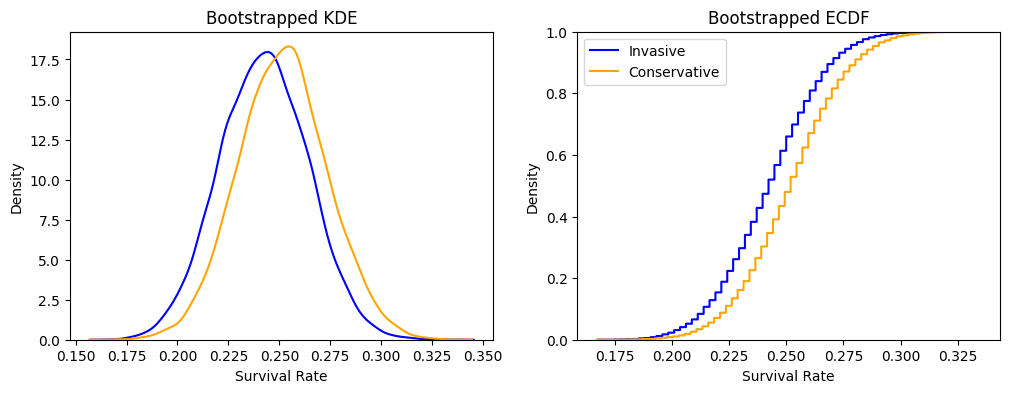

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

THe conservative group on average seems to have a higher survival rate than the invasive group, as indicated by both the KDE plot and the ECDF plot. They both have higher densities of higher survival rates overall, thus giving more evidence that the conservative treatment is more effective. 

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

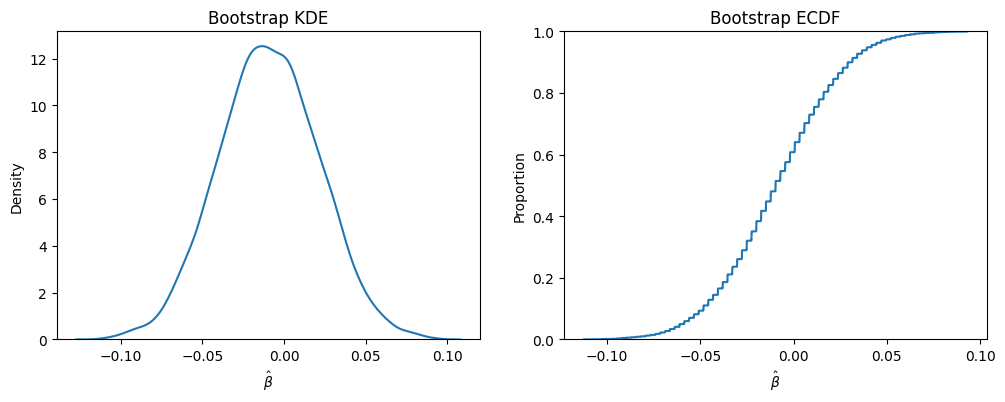

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


The bootstrap KDE does roughly have a bell shape. THe range of values possible seem to be between roughly -0.10 and 0.10, with the bell shape being fairly wide indicating some uncertainty. 

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05867642  0.04179366]
95% CI: [-0.06885899  0.05208322]
99% CI: [-0.08947076  0.07016411]


We fail to reject the null hypothesis for all three intervals, as 0 is contained within all of them. 

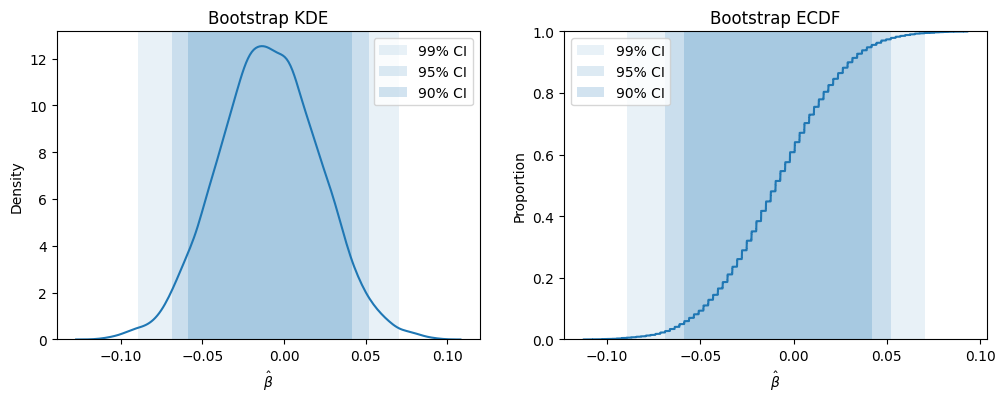

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

It doesn't seem to make much of a difference in treatment compared to not inserting balloons into hearts. This is evidenced by 0 being contained in all three confidence intervals, and the bootstrap KDE being extremely close to the normal distribution. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [11]:
diabetes = pd.read_csv('diabetes.csv')
print(diabetes['treatment'].value_counts())

treatment
lifestyle    234
rosi         233
met          232
Name: count, dtype: int64


In [12]:
diabetes.head()

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [13]:
#1

print(pd.crosstab( diabetes['treatment'], diabetes['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [15]:
#2

## Bootstrapping:
R = 10000
diabetes['success'] = (diabetes['outcome'] == 'success').astype(int)

diab_l = diabetes.loc[ diabetes['treatment'] == 'lifestyle',:]
diab_m = diabetes.loc[ diabetes['treatment'] == 'met',:]
diab_r = diabetes.loc[diabetes['treatment'] == 'rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_lt = diab_l.sample(frac=1.0, replace=True)
    df_mt = diab_m.sample(frac=1.0, replace=True)
    df_rt = diab_r.sample(frac = 1.0, replace = True)

    ## Evaluate outcomes:
    olt = df_lt['success'].mean() 
    omt = df_mt['success'].mean()  
    ort = df_rt['success'].mean() 
    

    ## Store results:
    outcome_l.append(olt) 
    outcome_m.append(omt) 
    outcome_r.append(ort)

outcome_l = np.array(outcome_l)
outcome_m = np.array(outcome_m)
outcome_r = np.array(outcome_r)

ate_m_vs_l = outcome_m - outcome_l
ate_r_vs_l = outcome_r - outcome_l
ate_r_vs_m = outcome_r - outcome_m

print(np.percentile(ate_m_vs_l, [2.5, 97.5]))


[-0.14187297  0.04273504]


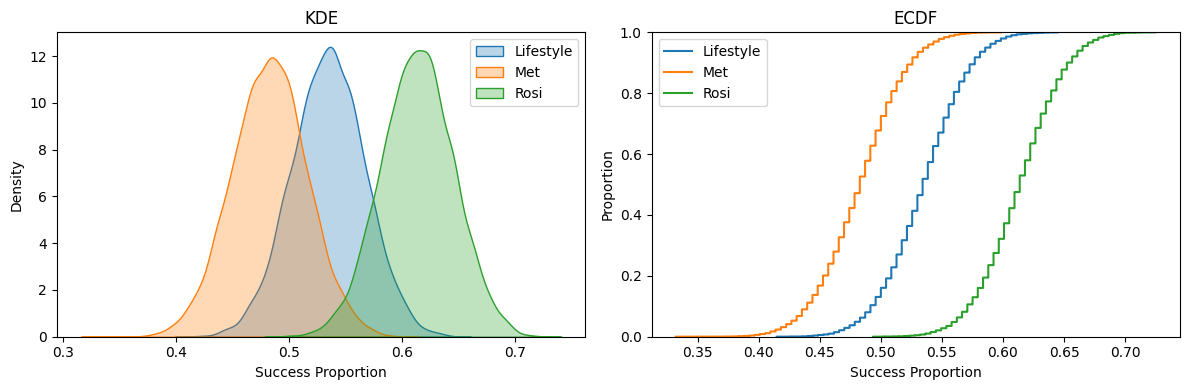

In [17]:

#c

boots = {
    'Lifestyle': np.array(outcome_l),
    'Met': np.array(outcome_m),
    'Rosi': np.array(outcome_r),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))


for label, vals in boots.items():
    sns.kdeplot(vals, ax=axes[0], label=label, fill=True, alpha=0.3)
axes[0].set_title('KDE')
axes[0].set_xlabel('Success Proportion')
axes[0].legend()


for label, vals in boots.items():
    sns.ecdfplot(vals, ax=axes[1], label=label)
axes[1].set_title('ECDF')
axes[1].set_xlabel('Success Proportion')
axes[1].legend()

plt.tight_layout()
plt.show()

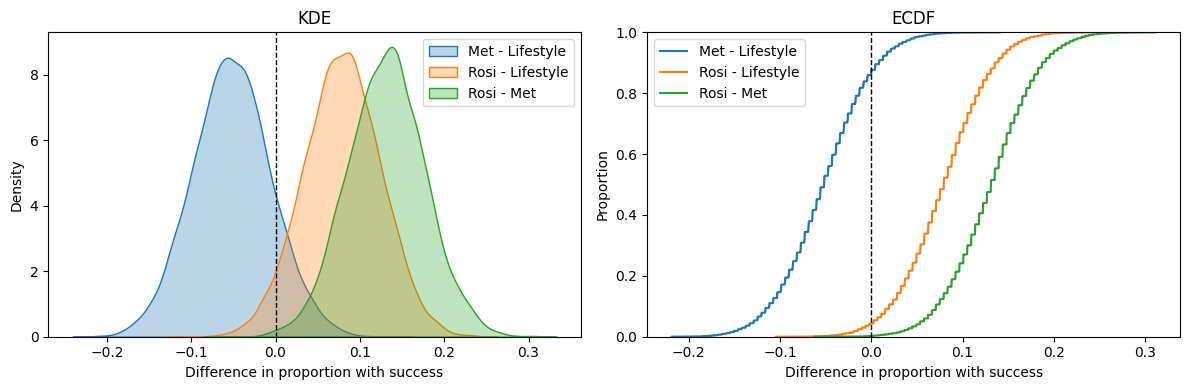

In [18]:
#d

l = np.array(outcome_l)
m = np.array(outcome_m)
r = np.array(outcome_r)

diffs = {
    'Met - Lifestyle': m - l,
    'Rosi - Lifestyle': r - l,
    'Rosi - Met': r - m,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))


for label, vals in diffs.items():
    sns.kdeplot(vals, ax=axes[0], label=label, fill=True, alpha=0.3)
axes[0].axvline(0, color='k', ls='--', lw=1)
axes[0].set_title('KDE')
axes[0].set_xlabel('Difference in proportion with success')
axes[0].legend()


for label, vals in diffs.items():
    sns.ecdfplot(vals, ax=axes[1], label=label)
axes[1].axvline(0, color='k', ls='--', lw=1)
axes[1].set_title('ECDF')
axes[1].set_xlabel('Difference in proportion with success')
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:

levels = [0.90, 0.95, 0.99]
rows = []
for label, vals in diffs.items():
    for lev in levels:
        alpha = 1 - lev
        low, high = np.quantile(vals, [alpha / 2, 1 - alpha / 2])
        rows.append({
            'Comparison': label,
            'Level': f'{int(lev*100)}%',
            'Lower': low,
            'Upper': high,
            'Contains 0': low <= 0 <= high,
        })

ci_table = pd.DataFrame(rows)
print(ci_table.round(4).to_string(index=False))

      Comparison Level   Lower  Upper  Contains 0
 Met - Lifestyle   90% -0.1286 0.0258        True
 Met - Lifestyle   95% -0.1419 0.0427        True
 Met - Lifestyle   99% -0.1712 0.0689        True
Rosi - Lifestyle   90%  0.0025 0.1524       False
Rosi - Lifestyle   95% -0.0105 0.1654        True
Rosi - Lifestyle   99% -0.0402 0.1952        True
      Rosi - Met   90%  0.0537 0.2083       False
      Rosi - Met   95%  0.0407 0.2214       False
      Rosi - Met   99%  0.0105 0.2513       False


Report:

Based on all of our findings, it is likely that rosi is the most effective out of the three diabetes treatments that were tested on, those being rosi, met, and lifestyle. However, this is not entirely certain. This is first evidenced by the simple proportion of success comparison; rosi's is far higher than the other two, with its success rate being 61% compared to met and lifestyle's success proportions of 48% and 53% respectively. However, obviously this testing was only done on one sample, so to get a fullproof comparison of the three treatments, I bootstrapped the outcomes for the three different treatments 10,000 times. This means that the data were resampled and had the same proportions calculated 10,000 times.

Based on the first KDE and ECDF plots above, there is more evidence that rosi is the most effective treatment. Both KDE plots and ECDFs essentially show the distribution of densities of different variables. In this case, the KDE shows the density og the different treatments' success rates, with rosi's density being clustered higher than the other two treatments. The ECDF shows the proportion of data below a certain value For the first ECDF plot, the other two treatments clearly show a lower success range than rosi again. 

For the second KDE and ECDF plots, these show the differences in success between each of the treatments, with each curve being one of the three possible comparisons. Both of the curves comparing rosi to the other two respective treatments have higher densities toward the positive differences, again showing that rosi has a higher success rate than the other two treatments. For both sets of KDE and ECDF plots, lifestyle seems to be the second best choice, as its success rates have a higher density than that of met, and the kde plot comparing met vs lifestyle is the only one whose densities cluster around the negative, meaning again that lifestyle is more effective than met. 

Finally, different confidence intervals were used to test the significance of the differences between the three treatments. All three confidence intervals comparing met and lifestyle contained 0 within them, which indicates no significant difference between the two treatments. For rosi vs lifestyle, the 90% confidence interval does not contain 0, however the 95% and 99% intervals do contain 0. This indicates that the difference between lifestyle and rosi is significant at the 90% level, but at higher significance levels the difference is not significant. This indicates that it is not entirely certain that rosi is more effective than met, as there is a greater than 5% chance that the difference between rosi and lifestyle is completely random. However, all three confidence levels confirm that rosi is significantly more effective than met, as none of the three confidence intervals contain 0. 

While rosi consistently outperformed lifestyle, it is still possible that this performance was due to random chance. However, rosi is clearly more effective than met, and its performance compared to lifestyle still suggests that rosi is likely to be the best treatment of the three. 